# Notebook: metricas de clasificación

**Introducción a la Ciencia de Datos 2026** · Posgrado en Ciencias de la Computación, CICESE

Luz Marey Lugo Acedo

Un banco portugués llamó por teléfono a sus clientes para ofrecerles un depósito a plazo. Solo uno de cada nueve aceptó (11.3 %). El banco quiere un modelo que le diga a quién llamar.

Datos: *Bank Marketing* con contexto socioeconómico (Moro, Cortez y Rita, 2014), del UCI Machine Learning Repository: 41 188 llamadas hechas entre mayo de 2008 y noviembre de 2010, con 20 variables y el objetivo `y` (¿el cliente contrató el depósito?).

**Puntos a evaluar:**
1. Qué variable el banco no conoce al decidir a quién llamar.
2. Partición 80/20 estratificada y la línea base de «siempre no».
3. Regresión logística con umbral 0.5 y sus métricas.
4. Curvas ROC y de precisión contra sensibilidad.
5. Umbral según costos y ganancias.
6. Qué pasa si se vuelve a incluir la variable quitada.

## Preparación

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
    accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

AZUL_OSCURO = "#112057"
AZUL = "#7697CD"
NARANJA = "#E76A28"
GRIS = "#5B6584"

plt.rcParams.update({
    "figure.dpi": 110, "axes.titlecolor": AZUL_OSCURO, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": AZUL_OSCURO, "axes.edgecolor": "#C9CFDF",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "axes.axisbelow": True, "grid.color": "#E3E6EF", "xtick.color": GRIS,
    "ytick.color": GRIS, "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=[AZUL_OSCURO, NARANJA, AZUL, GRIS]),
})

SEMILLA = 42

## Exploración de los datos



In [2]:
URL = ("https://github.com/mareylugo/ICD-2026/raw/refs/heads/main/Tareas/"
       "Notebook%20preprocesamiento/notebook%20metricas%20de%20clasificacion/bank-additional-full.csv")
try:
    banco = pd.read_csv("bank-additional-full.csv", sep=";")
except FileNotFoundError:
    banco = pd.read_csv(URL, sep=";")

y = (banco["y"] == "yes").astype(int)      # 1 = aceptó el depósito
X_todas = banco.drop(columns="y")

print(f"{banco.shape[0]} llamadas × {banco.shape[1]} columnas · faltantes: {int(banco.isna().sum().sum())}")
print(f"Aceptaron: {y.sum()} de {len(y)} ({y.mean():.1%}), uno de cada {1 / y.mean():.1f}")
banco.head(3)

41188 llamadas × 21 columnas · faltantes: 0
Aceptaron: 4640 de 41188 (11.3%), uno de cada 8.9


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Tamaño: 41 188 llamadas (filas), 20 variables de entrada y la variable objetivo y. No hay valores nulos, pero varias categóricas usan la etiqueta unknown como dato faltante. El archivo usa ; como separador.

Variable objetivo: y indica si el cliente contrató el depósito. Solo 11.3 % dijo que sí (4 640 clientes), así que está muy desbalanceado.

Variables del cliente: edad, tipo de trabajo, estado civil, educación y si tiene crédito en mora, hipoteca o préstamo personal.

Variables del contacto: tipo de teléfono, mes y día de la semana, número de contactos en la campaña actual (campaign), días desde un contacto anterior (pdays, donde 999 significa «no contactado antes»), contactos previos y resultado de la campaña anterior.

Contexto económico: cinco indicadores públicos (variación del empleo, índice de precios, confianza del consumidor, euribor a 3 meses y número de empleados).
duration: duración de la llamada en segundos. Solo se conoce después de llamar.

## 1. ¿Qué variable no se conoce al decidir a quién llamar?

El diccionario (`bank-additional-names.txt`) lo dice con todas sus letras sobre `duration`, la duración de la última llamada en segundos.

In [3]:
print(banco.groupby("y")["duration"].agg(["mean", "median"]).round(0).rename(
    columns={"mean": "promedio (s)", "median": "mediana (s)"}))
print(f"\nAUC de usar solo duration como puntaje: {roc_auc_score(y, banco['duration']):.3f}")
print(f"Llamadas con duration = 0: {(banco['duration'] == 0).sum()}, "
      f"con y = sí: {int(y[banco['duration'] == 0].sum())}")

     promedio (s)  mediana (s)
y                             
no          221.0        164.0
yes         553.0        449.0

AUC de usar solo duration como puntaje: 0.818
Llamadas con duration = 0: 4, con y = sí: 0


**Respuesta.** `duration` solo se conoce cuando la llamada ya terminó, y para entonces el banco ya pagó por ella y ya sabe si el cliente aceptó. Es casi una consecuencia del resultado: quien acepta suele hablar más del doble (el promedio es de unos 553 s contra 220 s) y, con ella sola como puntaje, se alcanza un AUC cercano a 0.82. Un modelo que la use parecería excelente y sería inservible para decidir a quién llamar, así que la quitamos, como recomienda el propio diccionario.

El resto de variables sí están disponibles antes de marcar. Las del contexto económico (`euribor3m`, `nr.employed`, etc.) son indicadores públicos, y `month` y `day_of_week` se conocen al planear la llamada. Hay un matiz con `campaign`, que cuenta los contactos de esta campaña *incluido el último*; la conservamos porque la tarea pide quitar una variable, pero conviene recordarlo.

In [4]:
X = X_todas.drop(columns="duration")
print(f"Variables para el modelo: {X.shape[1]}")

Variables para el modelo: 19


## 2. Partición estratificada y la línea base de «siempre no»

Apartamos 20 % para prueba. Con `stratify=y` los dos conjuntos conservan la misma proporción de clientes que aceptan.

In [5]:
X_ent, X_pru, y_ent, y_pru = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA)

print(f"Entrenamiento: {len(X_ent)} · Prueba: {len(X_pru)}")
print(f"Aceptan en entrenamiento: {y_ent.mean():.2%} · en prueba: {y_pru.mean():.2%}")

siempre_no = DummyClassifier(strategy="most_frequent").fit(X_ent, y_ent)
pred_no = siempre_no.predict(X_pru)
print(f"\nExactitud de responder siempre «no»: {accuracy_score(y_pru, pred_no):.2%}")
print(f"Clientes que aceptan y detecta:       {recall_score(y_pru, pred_no):.0%}")

Entrenamiento: 32950 · Prueba: 8238
Aceptan en entrenamiento: 11.27% · en prueba: 11.26%

Exactitud de responder siempre «no»: 88.74%
Clientes que aceptan y detecta:       0%


**Respuesta.** Un clasificador que siempre responde «no» acierta 88.7 % en prueba sin mirar un solo dato. Eso significa que la exactitud casi no distingue un modelo útil de uno que no hace nada: con una clase tan dominante, cualquier modelo tiene que superar 88.7 % para siquiera empatar. Además esa respuesta jamás encuentra a un cliente que acepta (sensibilidad de 0 %), que es justo para lo que el banco quiere el modelo. Necesitamos métricas que miren la clase pequeña.

## 3. Regresión logística con umbral 0.5

Las variables categóricas pasan por *one-hot* y las numéricas se estandarizan, todo dentro de un `Pipeline` para que el escalador y el codificador se ajusten solo con el entrenamiento.

In [6]:
def armar_modelo(columnas):
    num = columnas.select_dtypes("number").columns
    cat = columnas.select_dtypes(exclude="number").columns
    pre = ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    return Pipeline([("pre", pre), ("logit", LogisticRegression(max_iter=1000))])

modelo = armar_modelo(X_ent).fit(X_ent, y_ent)
p_pru = modelo.predict_proba(X_pru)[:, 1]     # probabilidad de aceptar

print(f"Columnas después del one-hot: {modelo.named_steps['pre'].transform(X_ent.head(1)).shape[1]}")
print(f"Probabilidad promedio predicha en prueba: {p_pru.mean():.3f} (real: {y_pru.mean():.3f})")

Columnas después del one-hot: 62
Probabilidad promedio predicha en prueba: 0.112 (real: 0.113)


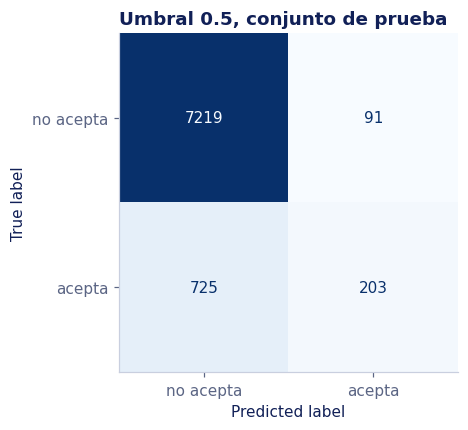

,umbral 0.5
VN,7219.000
FP,91.000
FN,725.000
VP,203.000
exactitud,0.901
precisión,0.690
sensibilidad,0.219
especificidad,0.988
F1,0.332


In [7]:
def metricas(y_real, p, umbral):
    pred = (p >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred).ravel()
    return {
        "VN": tn, "FP": fp, "FN": fn, "VP": tp,
        "exactitud": (tp + tn) / (tp + tn + fp + fn),
        "precisión": tp / (tp + fp) if tp + fp else 0.0,
        "sensibilidad": tp / (tp + fn),
        "especificidad": tn / (tn + fp),
        "F1": 2 * tp / (2 * tp + fp + fn),
    }

m05 = metricas(y_pru, p_pru, 0.5)

# Verificación contra scikit-learn
pred05 = (p_pru >= 0.5).astype(int)
assert np.isclose(m05["exactitud"], accuracy_score(y_pru, pred05))
assert np.isclose(m05["precisión"], precision_score(y_pru, pred05))
assert np.isclose(m05["sensibilidad"], recall_score(y_pru, pred05))
assert np.isclose(m05["F1"], f1_score(y_pru, pred05))

fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay.from_predictions(
    y_pru, pred05, display_labels=["no acepta", "acepta"], cmap="Blues", colorbar=False, ax=ax)
ax.grid(False)
ax.set_title("Umbral 0.5, conjunto de prueba")
plt.show()

pd.Series({k: (int(v) if k in ("VN", "FP", "FN", "VP") else round(v, 3)) for k, v in m05.items()}).to_frame("umbral 0.5")

**Respuesta.** Con el umbral de 0.5 el modelo acierta 90.1 % (contra 88.7 % de «siempre no»), pero casi todo ese acierto viene de los que no aceptan: la especificidad es de 98.8 % y la sensibilidad, de solo 21.9 %. De los 928 clientes que sí aceptaron en prueba, detecta 203 y deja ir 725. Cuando dice «llama» acierta 69 % de las veces (precisión), y el F1 queda en 0.33.

La métrica que más le importa al banco es la **sensibilidad**: cada cliente que acepta vale 50 y no detectarlo es dinero perdido, mientras que una llamada de más solo cuesta 5. Perder un cliente que acepta es nueve veces más caro que llamar de más, así que al banco le conviene tolerar falsas alarmas.

## 4. Curva ROC y curva de precisión contra sensibilidad

Ambas recorren **todos** los umbrales a la vez. Marcamos con círculos el umbral de 0.5 y el de 0.10.

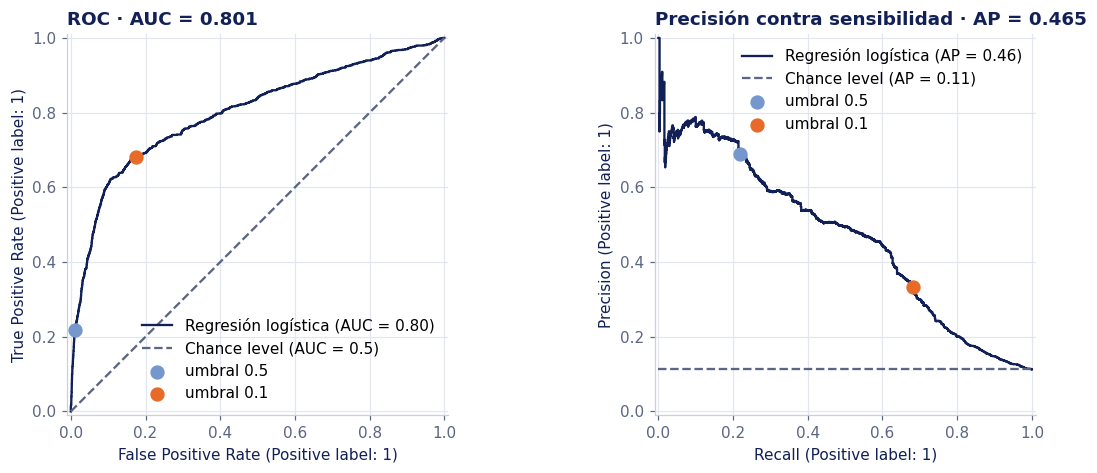

AUC = 0.801 · precisión promedio (AP) = 0.465 · AP de un modelo al azar = 0.113


In [8]:
auc = roc_auc_score(y_pru, p_pru)
ap = average_precision_score(y_pru, p_pru)
m10 = metricas(y_pru, p_pru, 0.10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))

RocCurveDisplay.from_predictions(
    y_pru, p_pru, ax=ax1, plot_chance_level=True,
    chance_level_kw={"color": GRIS, "linestyle": "--"}, name="Regresión logística")
for m, t, c in [(m05, 0.5, AZUL), (m10, 0.10, NARANJA)]:
    ax1.scatter(1 - m["especificidad"], m["sensibilidad"], s=70, color=c, zorder=5, label=f"umbral {t}")
ax1.set_title(f"ROC · AUC = {auc:.3f}")
ax1.legend(loc="lower right")

PrecisionRecallDisplay.from_predictions(
    y_pru, p_pru, ax=ax2, plot_chance_level=True,
    chance_level_kw={"color": GRIS, "linestyle": "--"}, name="Regresión logística")
for m, t, c in [(m05, 0.5, AZUL), (m10, 0.10, NARANJA)]:
    ax2.scatter(m["sensibilidad"], m["precisión"], s=70, color=c, zorder=5, label=f"umbral {t}")
ax2.set_title(f"Precisión contra sensibilidad · AP = {ap:.3f}")
ax2.legend(loc="upper right")

fig.tight_layout()
plt.show()

print(f"AUC = {auc:.3f} · precisión promedio (AP) = {ap:.3f} · AP de un modelo al azar = {y_pru.mean():.3f}")

**Respuesta.** La ROC se ve buena (AUC de 0.80) porque su eje horizontal es la tasa de falsos positivos, que se mide contra los 7 310 clientes que no aceptan: aun cuando el modelo se equivoca con cientos de ellos, esa tasa sigue pareciendo pequeña. La curva de precisión contra sensibilidad no tiene ese colchón, porque la precisión cuenta las falsas alarmas contra las llamadas que se hacen, y ahí aparece lo que la ROC esconde: para detectar a 68 % de los que aceptan (umbral de 0.10) la precisión cae a 33 %, o sea que solo una de cada tres llamadas sirve. La precisión promedio es de 0.46, lejos de 1 aunque muy por arriba de 0.11, que es lo que lograría un modelo al azar. Con pocos positivos, la segunda curva es la que cuenta cuánto cuesta cada cliente adicional que se detecta.

## 5. ¿A partir de qué probabilidad conviene llamar?

Llamar cuesta 5 y un cliente que acepta deja 50. Si la probabilidad de aceptar es *p*, la ganancia esperada de llamar es

$$50\,p - 5 \;\geq\; 0 \quad\Longleftrightarrow\quad p \;\geq\; \frac{5}{50} = 0.10$$

Conviene llamar en cuanto la probabilidad llegue a 10 %. Esto es una decisión económica, no estadística: el umbral sale de los costos, sin mirar la prueba. Que funcione depende de que las probabilidades sean confiables, y lo son aquí: el modelo predice en promedio 0.11 y la tasa real es 0.11.

In [9]:
COSTO_LLAMADA, INGRESO = 5, 50

def ganancia(y_real, p, umbral):
    llamar = p >= umbral
    aceptan = int((llamar & (y_real == 1)).sum())
    return INGRESO * aceptan - COSTO_LLAMADA * int(llamar.sum()), int(llamar.sum()), aceptan

umbral_costos = COSTO_LLAMADA / INGRESO
filas = {}
for nombre, t in [("umbral 0.5", 0.5), (f"umbral {umbral_costos:.2f} (por costos)", umbral_costos)]:
    g, llamadas, aceptan = ganancia(y_pru, p_pru, t)
    filas[nombre] = {"llamadas": llamadas, "aceptan": aceptan, "ganancia": g}

g_todos, ll_todos, ac_todos = ganancia(y_pru, np.ones(len(y_pru)), 0.0)
filas["llamar a todos"] = {"llamadas": ll_todos, "aceptan": ac_todos, "ganancia": g_todos}
filas["no llamar a nadie"] = {"llamadas": 0, "aceptan": 0, "ganancia": 0}
filas["oráculo (solo a quienes aceptan)"] = {
    "llamadas": int(y_pru.sum()), "aceptan": int(y_pru.sum()),
    "ganancia": (INGRESO - COSTO_LLAMADA) * int(y_pru.sum())}

tabla = pd.DataFrame(filas).T
tabla

,llamadas,aceptan,ganancia
umbral 0.5,294,203,8680
umbral 0.10 (por costos),1900,632,22100
llamar a todos,8238,928,5210
no llamar a nadie,0,0,0
oráculo (solo a quienes aceptan),928,928,41760


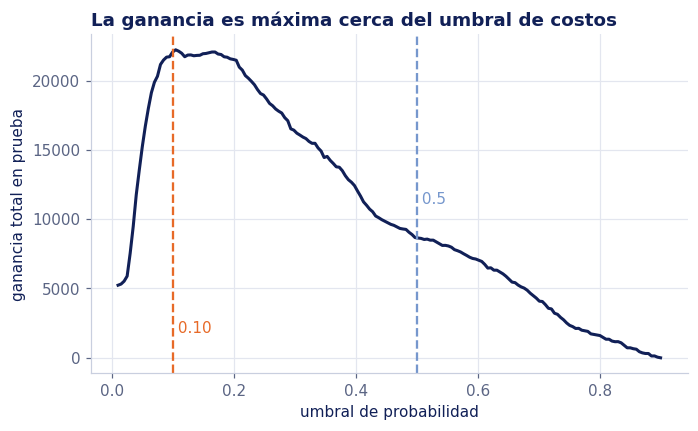

Máximo en prueba: umbral 0.10, ganancia 22,215 (con 0.10: 22,100)


In [10]:
ts = np.linspace(0.01, 0.90, 180)
gs = [ganancia(y_pru, p_pru, t)[0] for t in ts]
t_mejor = ts[int(np.argmax(gs))]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ts, gs, color=AZUL_OSCURO, linewidth=2)
ax.axvline(0.5, color=AZUL, linestyle="--")
ax.axvline(umbral_costos, color=NARANJA, linestyle="--")
ax.text(0.5, max(gs) * 0.5, " 0.5", color=AZUL)
ax.text(umbral_costos, max(gs) * 0.08, " 0.10", color=NARANJA)
ax.set_xlabel("umbral de probabilidad")
ax.set_ylabel("ganancia total en prueba")
ax.set_title("La ganancia es máxima cerca del umbral de costos")
plt.show()

print(f"Máximo en prueba: umbral {t_mejor:.2f}, ganancia {max(gs):,.0f} "
      f"(con 0.10: {ganancia(y_pru, p_pru, 0.10)[0]:,.0f})")

**Respuesta.** Conviene llamar a todo cliente cuya probabilidad de aceptar sea al menos 0.10. Con ese umbral la ganancia en prueba es de 22 100, contra 8 680 con el umbral de 0.5: más del doble (+155 %). El de 0.5 es demasiado conservador, porque solo llama a 294 clientes y deja de llamar a muchos que valen la pena; el de 0.10 hace 1 900 llamadas, mucho más caras en total, pero detecta a 632 clientes que aceptan contra 203. Llamar a todos deja 5 210 y no llamar a nadie, 0, así que el modelo sí agrega valor. El máximo de la curva (22 215) también cae en 0.10, es decir, el umbral que salió de los costos coincide con el óptimo y se obtuvo sin mirar la prueba. La curva es bastante plana entre 0.10 y 0.20, así que elegir un umbral un poco más alto casi no cambia la ganancia, mientras que uno por encima de 0.3 sí la reduce con claridad. El tope teórico, llamar solo a quienes aceptan, sería 41 760, y el modelo logra algo más de la mitad.

## 6. La variable que quitamos

Repetimos el punto 3 con `duration` incluida, con la misma partición.

In [11]:
X_ent_d = X_todas.loc[X_ent.index]
X_pru_d = X_todas.loc[X_pru.index]

modelo_d = armar_modelo(X_ent_d).fit(X_ent_d, y_ent)
p_pru_d = modelo_d.predict_proba(X_pru_d)[:, 1]

def resumen(p):
    m = metricas(y_pru, p, 0.5)
    return {
        "exactitud": m["exactitud"], "precisión": m["precisión"], "sensibilidad": m["sensibilidad"],
        "especificidad": m["especificidad"], "F1": m["F1"],
        "AUC": roc_auc_score(y_pru, p), "AP": average_precision_score(y_pru, p),
        "ganancia con 0.5": ganancia(y_pru, p, 0.5)[0],
        "ganancia con 0.10": ganancia(y_pru, p, 0.10)[0],
    }

comparacion = pd.DataFrame({"sin duration": resumen(p_pru), "con duration": resumen(p_pru_d)})
comparacion.round(3)

,sin duration,con duration
exactitud,0.901,0.917
precisión,0.690,0.712
sensibilidad,0.219,0.436
especificidad,0.988,0.978
F1,0.332,0.541
AUC,0.801,0.942
AP,0.465,0.636
ganancia con 0.5,8680.000,17405.000
ganancia con 0.10,22100.000,32860.000


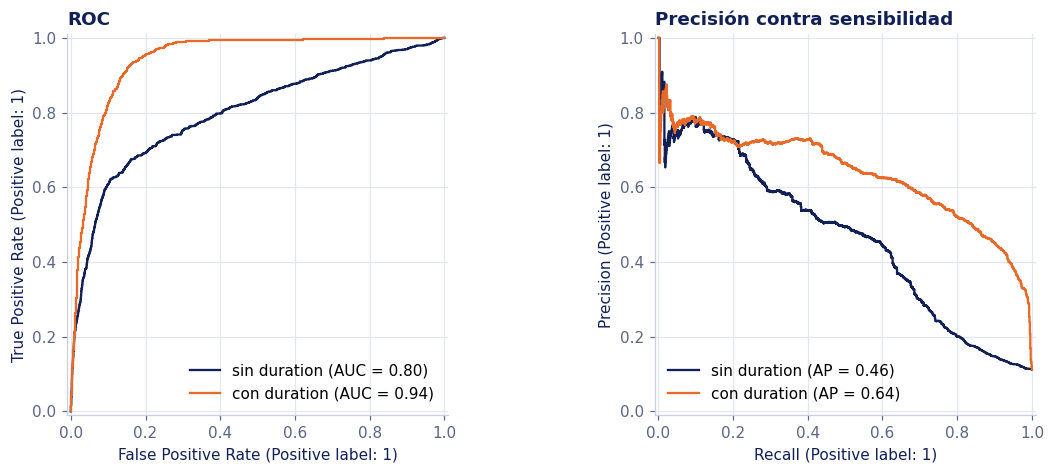

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
for p, nombre in [(p_pru, "sin duration"), (p_pru_d, "con duration")]:
    RocCurveDisplay.from_predictions(y_pru, p, ax=ax1, name=nombre)
    PrecisionRecallDisplay.from_predictions(y_pru, p, ax=ax2, name=nombre)
ax1.set_title("ROC")
ax2.set_title("Precisión contra sensibilidad")
fig.tight_layout()
plt.show()

**Respuesta.** Las métricas mejoran mucho: con el umbral de 0.5 la sensibilidad sube de 0.22 a 0.44, el F1 de 0.33 a 0.54, el AUC de 0.80 a 0.94 y la precisión promedio de 0.46 a 0.64, y la ganancia con el umbral de 0.10 pasa de 22 100 a 32 860. Sin embargo, **no le servirían al banco**. La duración de la llamada solo existe cuando la llamada ya se hizo: para decidir a quién llamar, el banco tendría que conocer un número que todavía no existe. Las métricas mejoran porque el modelo ve algo que es en buena parte *consecuencia* del resultado (quien va a aceptar se queda hablando), no porque entienda mejor a los clientes. Es una fuga de información: sirve para describir qué pasó en las llamadas ya hechas, y el modelo realista es el del punto 3, con sus 0.80 de AUC.




## Declaración de uso de IA generativa

Se utilizó el asistente de inteligencia artificial Claude (Anthropic) en la elaboración de este notebook. La autora revisó el contenido y es responsable de su exactitud.

## Referencias

- Moro, S., Cortez, P. y Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems*, 62, 22-31.
- UCI Machine Learning Repository: *Bank Marketing*.
- Pedregosa, F. *et al.* (2011). Scikit-learn: Machine learning in Python. *JMLR*, 12, 2825-2830.
- Saito, T. y Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE*, 10(3), e0118432.